In [2]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
import numpy as np

In [3]:
requests.get('https://www.ambitionbox.com/list-of-companies?campaign=mob_hamburger')

<Response [403]>

# if response code is 403
 - headers={'User-Agent':'Mozilla/5.0 (Windows NT 6.3; Win 64 ; x64) Apple WeKit /537.36(KHTML , like Gecko) Chrome/80.0.3987.162 Safari/537.36'}
 -requests.get('url',headers=headers).text

In [4]:
headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 6.3; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko)'
}
webpage = requests.get('https://www.ambitionbox.com/list-of-companies?campaign=mob_hamburger', headers=headers).text

In [5]:
soup=BeautifulSoup(webpage,'lxml')

<!DOCTYPE html>
<html lang="en">
 <head>
  <meta charset="utf-8"/>
  <title>
   Verify - AmbitionBox
  </title>
  <meta content="Verify - AmbitionBox" name="title"/>
  <meta content="Complete a quick security check to continue to AmbitionBox." name="description"/>
  <meta content="width=device-width,initial-scale=1, minimum-scale=1, interactive-widget=resizes-content" name="viewport"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_16x16.png" rel="icon" sizes="16x16" type="image/png"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_32x32.png" rel="icon" sizes="32x32" type="image/png"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_48x48.png" rel="icon" sizes="48x48" type="image/png"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_96x96.png" rel="icon" sizes="96x96" type="image/png"/>
  <link href="https://static.ambitionbox.com/al
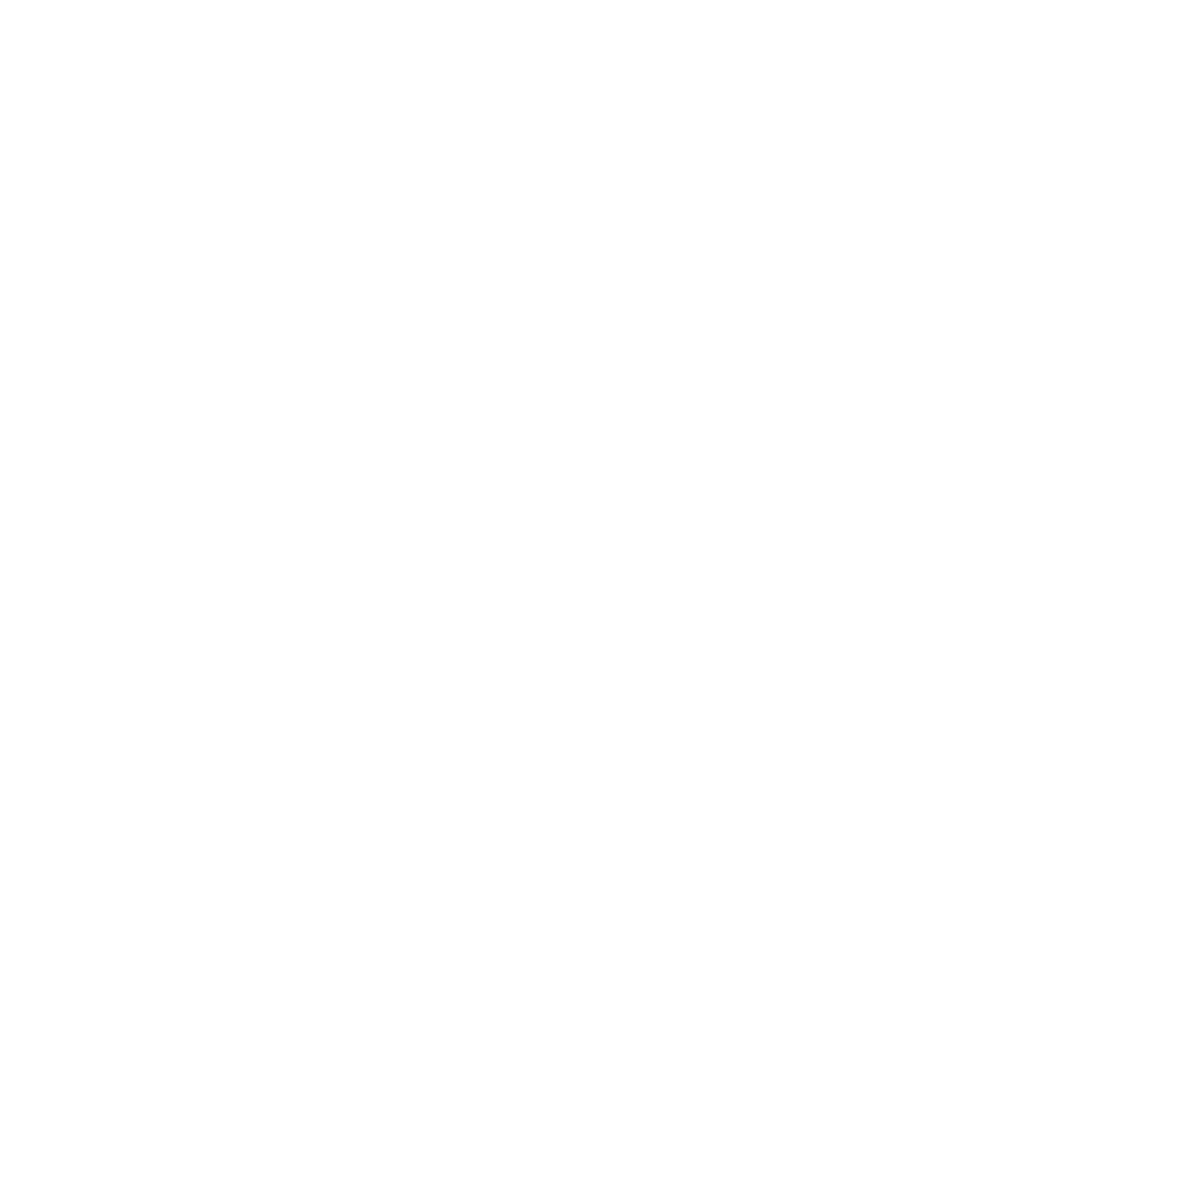

In [6]:
print(soup.prettify())

In [7]:
soup.find_all('h1')[0].text.strip()

'Let’s make sure it’s you'

# TO FIND OUT NAMES OF THE COMPANIES

In [8]:
soup.find_all('h2')

[]

In [8]:
len(soup.find_all('h2'))

0

In [9]:
for i in soup.find_all('h2'):
    print(i.text.strip())

## TO FIND OUT THE RATINGS

In [10]:
for i in soup.find_all('span', class_='text-primary-text font-pn-700 text-sm !text-[14px] !leading-[14px]'):
    print(i.text.strip())

## TO FIND OUT THE NUMBER OF REVIEWS

In [11]:
for i in soup.find_all('span',  class_='pl-1 text-[14px] font-pn-400 leading-5 text-[#4E597B] max-md:text-[12px]'):
    print(i.text.strip())

In [12]:
len(soup.find_all('span', class_='pl-1 text-[14px] font-pn-400 leading-5 text-[#4E597B] max-md:text-[12px]'))

0

# Find location

In [13]:
for i in soup.find_all('span', class_='overflow-hidden text-left text-[14px] font-pn-400 leading-5 tracking-[0.25px] text-[#394468] max-md:text-[12px] max-md:leading-4'):
    print(i.text.strip())



In [14]:
len(soup.find_all('span', class_='overflow-hidden text-left text-[14px] font-pn-400 leading-5 tracking-[0.25px] text-[#394468] max-md:text-[12px] max-md:leading-4'))

0

# CONSIDERING THE WHOLE CONTAINER



In [15]:
company = soup.find_all('div',class_='flex cursor-pointer px-5 pt-5 gap-2 max-md:px-3 max-md:pt-4')

In [16]:
len(company) 

0

In [ ]:
name=[]
rating=[]
reviews=[]

for i in company:

  name.append(i.find('h2').text.strip())
  rating.append(i.find('span', class_='text-primary-text font-pn-700 text-sm !text-[14px] !leading-[14px]').text.strip())
  reviews.append(i.find('span',  class_='pl-1 text-[14px] font-pn-400 leading-5 text-[#4E597B] max-md:text-[12px]').text.strip())

df=pd.DataFrame({
   'name':name,
   'rating':rating,
   'reviews':reviews,
})


In [18]:
name

[]

In [19]:
rating

[]

In [20]:
reviews


[]

In [21]:
df = pd.DataFrame(df)


In [22]:
df.shape

(0, 3)

# creating final dataframe for all the pages

In [ ]:
final = []

for j in range(1, 11):

    url = 'https://www.ambitionbox.com/list-of-companies?campaign=mob_hamburger&page={}'.format(j)

    webpage = requests.get(url, headers=headers)   # <-- sirf yahan headers add kiya
    soup = BeautifulSoup(webpage.text, 'lxml')

    company = soup.find_all('div', class_='flex cursor-pointer px-5 pt-5 gap-2 max-md:px-3 max-md:pt-4')

    name = []
    rating = []
    reviews = []

    for i in company:

        name.append(i.find('h2').text.strip())

        rating.append(i.find('span', class_='text-primary-text font-pn-700 text-sm !text-[14px] !leading-[14px]').text.strip())

        reviews.append(i.find('span', class_='pl-1 text-[14px] font-pn-400 leading-5 text-[#4E597B] max-md:text-[12px]').text.strip())

    df = pd.DataFrame({
        'name': name,
        'rating': rating,
        'reviews': reviews
    })

    final.append(df)

final = pd.concat(final, ignore_index=True)

In [1]:
final

NameError: name 'final' is not defined

In [ ]:
final.shape

(30000, 7)